## Mini Batch

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from utils import SIZE, CLASSES, prepare_data_set, plot_costs, load_image, get_label
from checks import check_l2_cost
from dnn import (
    relu, sigmoid, initialize_parameters, activate,
    ActivationCache, PropagateCache, ForwardCache,
    propagate, propagate_backward,
    AL_derivative, relu_backward, sigmoid_backward,
)

In [2]:
datasets = prepare_data_set()

Y_train = datasets["Y_train"]
X_train = datasets ["X_train"]
X_test = datasets["X_test"]
Y_test = datasets["Y_test"]
X_test_orig_set = datasets["X_test_orig_set"]
X_train_orig_set = datasets["X_train_orig_set"]


In [3]:
def forward_pass(X, parameters):
    # find the number of layers from the initialized parameters
    L = len(parameters) // 2

    # print(f"Len Layer: {L}")
    cache = [] # we need this later for backward propagation
    Aprev = X # initial assignment to A0
    for l in range(0,L):
        # here we calculate Zl     
        Zl, pc = propagate(parameters["W"+str(l+1)], Aprev, parameters["b"+str(l+1)])
        # here we calculate Al (it should be started from 1 by the loop)
        if (l == (L-1)): # for output layer, we use sigmoid
            Aprev, ac= activate(Zl, "sigmoid")
        else:
            Aprev, ac= activate(Zl, "relu")
        forward_cache = ForwardCache(PropagateCache = pc, ActivationCache=ac) 
        cache.append(forward_cache)
    output = Aprev
    # print(f"Len in forward: {len(cache)} {len(parameters)} ")
    return output, cache

In [24]:
def backward_pass(AL, Y, caches):

    grads = {}
    L = len(caches)
    current_layer_cache = caches[L-1]
    current_layer_W = current_layer_cache.PropagateCache.W
    current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
    
    # get the dZ for outer/output layer
    # sigmoid + binary cross-entropy simplifies to dZ = AL - Y
    dZ = AL-Y
    dW,db, dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W )
    grads["dW"+str(L)] = dW
    grads["db"+str(L)] = db

    # print(f"l in backward = {L}")
    
    for l in reversed (range (L-1)):
        current_layer_cache = caches[l]
        current_layer_W = current_layer_cache.PropagateCache.W
        current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
        dZ = relu_backward(dAprev, current_layer_cache.ActivationCache)
        dW,db,dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W)
        # print(f"l in backward = {l+1}")
        grads["dW" + str(l+1)] = dW
        grads["db" + str(l+1)] = db
    

    # print(f"grads: {len(grads)}")

    # for l in range (1, L+1):
    #     print(f"grads: {grads["dW" + str(l)].shape}")
    
    return grads


def backward_pass_L2(AL, Y, caches, lambd):
    grads = backward_pass(AL,Y, caches)
    L = len(caches)
    m = AL.shape[1]
    for l in reversed (range (0, L)):
        cc = caches[l].PropagateCache
        grads["dW"+str(l+1)] = grads["dW"+str(l+1)] + ((lambd / m) * cc.W)
        
    return grads
    


In [23]:
def calculate_cost(AL,Y):
    m = AL.shape[1]
    # clip AL to avoid log(0).
    AL = np.clip(AL, 1e-8, 1 - 1e-8)
    cost =  -(1./m) * np.sum((np.dot(Y,np.log(AL).T) + np.dot(1-Y, np.log(1-AL).T)))
    # make sure the output not a 0-dimensional array/scalar
    # eg 2D array (matrix) number: [[24]] => become 24.
    res = np.squeeze(cost)
    return res

def calculate_cost_L2(AL,Y, parameters, lambd):
    cost = calculate_cost(AL,Y)
    m = AL.shape[1]
    L = len(parameters)//2
    Wl = []
    for l in range(1,L+1):
        W = np.sum(np.square(parameters["W"+str(l)]))
        Wl.append(W)

    L2_regularization_cost = (lambd / (2 * m)) * np.sum(Wl)
    cost = cost + L2_regularization_cost
    return cost

In [46]:
def initialize_adam(parameters):
    L = len(parameters) // 2

    s = {}
    v = {}

    for l in range (1, L + 1):
        v["dW"+str(l)] = np.zeros(parameters["W"+str(l)].shape)
        v["db"+str(l)] = np.zeros(parameters["b"+str(l)].shape)
        s["dW"+str(l)] = np.zeros(parameters["W"+str(l)].shape)
        s["db"+str(l)] = np.zeros(parameters["b"+str(l)].shape)
    return v,s

def update_parameter(parameters, grads, learning_rate):

    # floor divide by 2 because each layer has both a 'W' and a 'b'
    L = len(parameters) // 2
    
    for l in range (0, L):
        parameters["W" + str(l+1)] = parameters["W" + str(l+1)] - (learning_rate * grads["dW"+str(l+1)])
        parameters["b" + str(l+1)] = parameters["b" + str(l+1)] - (learning_rate * grads["db"+str(l+1)])

    assert len(grads) == len(parameters)
    return parameters

def update_parameter_w_adam(parameters, grads, v,s,t, learning_rate, beta1 = 0.9, beta2 = 0.999,  epsilon = 1e-8):

    L = len(parameters) // 2
    v_corrected = {}
    s_corrected = {}
    for l in range (1, L +1):
        v["dW" + str(l)] = beta1 * v["dW"+str(l)] + (1 - beta1) * grads["dW"+str(l)]
        v["db" + str(l)] = beta1 * v["db"+str(l)] + (1 - beta1) * grads["db"+str(l)]
        v_corrected["dW"+ str(l)] = v["dW" + str(l)] / (1 - np.power(beta1, t))
        v_corrected["db"+ str(l)] = v["db" + str(l)] / (1 - np.power(beta1, t))

        s["dW" + str(l)] = beta2 * s["dW" + str(l)] + (1-beta2) * np.power(grads["dW"+str(l)], 2)
        s["db" + str(l)] = beta2 * s["db" + str(l)] + (1-beta2) * np.power(grads["db"+str(l)], 2)

        s_corrected["dW" + str(l)] = s["dW" + str(l)]  / (1 - np.power(beta2, t)) 
        s_corrected["db" + str(l)] = s["db" + str(l)]  / (1 - np.power(beta2, t))


        parameters["W"+str(l)] = parameters["W"+str(l)] - (learning_rate * v_corrected["dW"+ str(l)]  / (np.sqrt(s_corrected["dW" + str(l)]) + epsilon))
        parameters["b"+str(l)] = parameters["b"+str(l)] - (learning_rate * v_corrected["db"+ str(l)]  / (np.sqrt(s_corrected["db" + str(l)]) + epsilon))

    return parameters



In [67]:
# classify will apply the propagation with the given parameters
# and return the classification as 1 or 0
def classify(X,parameters):
    output, _ = forward_pass(X,parameters)
    return (output > 0.5).astype(int)


def random_mini_batches(X, Y, mini_batch_size=64, seed=3):
    np.random.seed(seed)
    m = X.shape[1]
    total_batches =  m // mini_batch_size

    permutation = list(np.random.permutation(m))
    shuffled_X = X[:, permutation]
    shuffled_Y = Y[:, permutation].reshape((1,m))

    mini_batches = []
    for k in range (0, total_batches):

        i = k * mini_batch_size
        j = (k+1) * mini_batch_size
        mini_X = shuffled_X[:, i:j]
        mini_Y = shuffled_Y[:, i:j]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)
    if m % mini_batch_size != 0:
        i = total_batches * mini_batch_size
        mini_X = shuffled_X[:, i:]
        mini_Y = shuffled_Y[:, i:]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)

    return mini_batches

def dnn_model(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, 
              learning_rate=0.0075, mini_batch_size=64, seed = 3, 
              lambd=1,   print_cost=False,
              beta1 = 0.9, beta2 = 0.999,  epsilon = 1e-8,
              decay=None, decay_rate=1
             ):
    
    parameters = initialize_parameters(layers_dims)
    v,s = initialize_adam(parameters)
    costs = []
    adam_t = 1
    learning_rate0=learning_rate
    for i in range(1,iteration+1):
        mini_batch_costs = []
        mini_batches = random_mini_batches(X_train, Y_train, mini_batch_size, seed+i)
        num_batches = len(mini_batches)
        for k in range (0, num_batches):
            X, Y = mini_batches[k]
            AL, cache = forward_pass(X, parameters)
            # cost = calculate_cost(AL,Y)
            cost = calculate_cost_L2(AL,Y, parameters, lambd)
            mini_batch_costs.append(cost)
            # grads = backward_pass(AL, Y, cache)
            grads = backward_pass_L2(AL, Y, cache, lambd)
            # parameters = update_parameter(parameters, grads, learning_rate) # enable if Adam is disabled
            parameters = update_parameter_w_adam(parameters, grads, v,s,adam_t, learning_rate, beta1, beta2, epsilon)
            adam_t +=1
        
        if (i%100 == 0) and print_cost:
            cost_avg = np.average(mini_batch_costs)
            print(f"Cost: {cost_avg}, learning_rate = {learning_rate}")
            costs.append(cost_avg)
        if decay:
            learning_rate = decay(learning_rate0, i, decay_rate)

    
    
    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, costs


In [57]:
def update_lr(learning_rate0, epoch_num, decay_rate):
    learning_rate = (1 / (1 + (epoch_num * decay_rate))) * learning_rate0

    return learning_rate

In [29]:
input_features= X_train.shape[0]
iteration = 2500
# learning_rate = 0.0075 # for non adam
learning_rate = 0.001
mini_batch_size = 128
lambd=1
layer_dims_deep = [input_features, 30, 20, 10, 1]
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
decay_rate = 1
parameter_deep, cost_deep = dnn_model(
        X_train=X_train, 
        Y_train=Y_train, 
        X_test=X_test, 
        Y_test=Y_test, 
        layers_dims=layer_dims_deep, 
        iteration=iteration, 
        learning_rate=learning_rate, 
        mini_batch_size=mini_batch_size, 
        lambd=lambd,
        print_cost=True,
        decay = update_lr,
        decay_rate=decay_rate)

Cost: 0.8038672177978295
Cost: 0.6479451903682376
Cost: 0.5587089596040461
Cost: 0.5719832433500562
Cost: 0.5140555655096737
Cost: 0.5517357261324926
Cost: 0.5000912786475105
Cost: 0.4391630287435447
Cost: 0.47292875349037305
Cost: 0.4691310066623488
Cost: 0.4783688343198504
Cost: 0.4599557472538831
Cost: 0.4602098859053244
Cost: 0.4649902306073922
Cost: 0.4650705690044445
Cost: 0.4758708356610769
Cost: 0.5126806707935017
Cost: 0.4687398762337397
Cost: 0.4597803627061471
Cost: 0.4075853834645177
Cost: 0.45194419451472034
Cost: 0.5005526881138356
Cost: 0.507038286694117
Cost: 0.42242658227679203
Cost: 0.5249676968957961
train_accuracy: 86.5584009993754%
test_accuracy: 59.76272862086011%


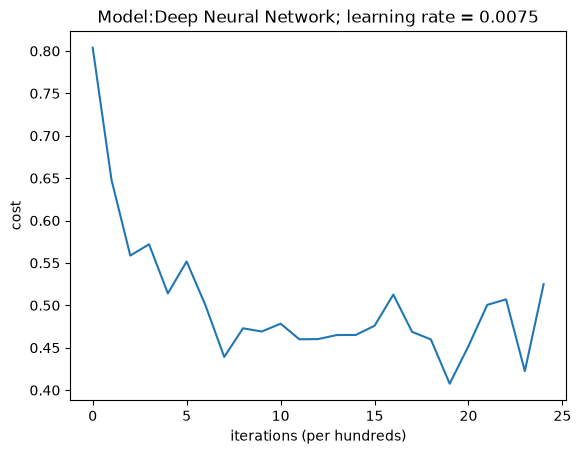

In [30]:
plot_costs(cost_deep, "Deep Neural Network", learning_rate)

In [52]:
input_features= X_train.shape[0]
iteration = 2500
# learning_rate = 0.0075 # for non adam
learning_rate = 0.001
mini_batch_size = 128
lambd=1
layer_dims_deep = [input_features, 30, 20, 10, 1]
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
parameter_deep, cost_deep = dnn_model(
        X_train=X_train, 
        Y_train=Y_train, 
        X_test=X_test, 
        Y_test=Y_test, 
        layers_dims=layer_dims_deep, 
        iteration=iteration, 
        learning_rate=learning_rate, 
        mini_batch_size=mini_batch_size, 
        lambd=lambd, print_cost=True,
        beta1 = beta1,
        beta2 = beta2,
        epsilon = epsilon,
        decay = update_lr,
        decay_rate=decay_rate)

Cost: 0.695881972147162
Cost: 0.6722142765099218
Cost: 0.670842707599315
Cost: 0.6683349994278726
Cost: 0.6834281282332698
Cost: 0.6709682677857303
Cost: 0.6682144503106204
Cost: 0.6516294201209576
Cost: 0.6479756494160966
Cost: 0.6491284171239201
Cost: 0.646026046502413
Cost: 0.6500450955327386
Cost: 0.649802805827832
Cost: 0.671506975358631
Cost: 0.6318131170968061
Cost: 0.6175247175926956
Cost: 0.6348059714423727
Cost: 0.6173176974815155
Cost: 0.6104530002329414
Cost: 0.6070802969322329
Cost: 0.6154608318633261
Cost: 0.6334372961031499
Cost: 0.6315516275614366
Cost: 0.6406660563350419
Cost: 0.6192988230551952
train_accuracy: 70.39350405996252%
test_accuracy: 58.03262481463173%


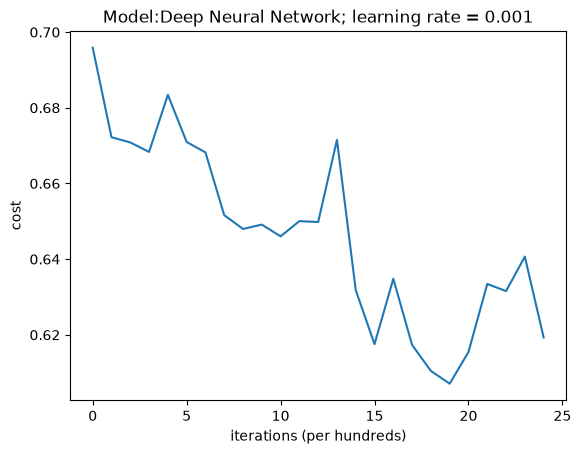

In [53]:
plot_costs(cost_deep, "Deep Neural Network", learning_rate)

In [54]:
input_features= X_train.shape[0]
iteration = 2500
# learning_rate = 0.0075 # for non adam
learning_rate = 0.001
mini_batch_size = 128
lambd=0
layer_dims_deep = [input_features, 30, 20, 10, 1]
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
parameter_deep, cost_deep = dnn_model(
        X_train=X_train, 
        Y_train=Y_train, 
        X_test=X_test, 
        Y_test=Y_test, 
        layers_dims=layer_dims_deep, 
        iteration=iteration, 
        learning_rate=learning_rate, 
        mini_batch_size=mini_batch_size, 
        lambd=lambd, print_cost=True,
        beta1 = beta1,
        beta2 = beta2,
        epsilon = epsilon,
        decay = update_lr,
        decay_rate=decay_rate)

Cost: 0.48548988088070316
Cost: 0.3031545184970826
Cost: 0.1818994228590719
Cost: 0.1215765052651748
Cost: 0.06930762292525262
Cost: 0.08193864216718093
Cost: 0.34830440893472064
Cost: 0.018916358176865454
Cost: 0.016710360334587428
Cost: 0.009588495805424433
Cost: 0.01265439348577826
Cost: 0.21902940375870011
Cost: 0.05629879832289288
Cost: 0.14289416706811003
Cost: 0.01790729359331753
Cost: 0.07789981791490903
Cost: 0.028984574950377567
Cost: 0.006945263355279608
Cost: 0.06070045133998052
Cost: 0.4779066417634895
Cost: 0.34628946465896
Cost: 0.3464710325288085
Cost: 0.19241756815933614
Cost: 0.1713028374345532
Cost: 0.14030659666129394
train_accuracy: 91.83010618363522%
test_accuracy: 56.40138408304498%


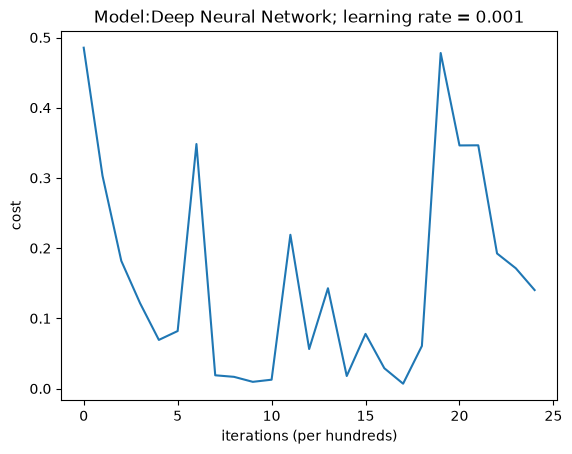

In [55]:
plot_costs(cost_deep, "Deep Neural Network", learning_rate)

In [66]:
input_features= X_train.shape[0]
iteration = 300
# learning_rate = 0.0075 # for non adam
learning_rate = 0.001
mini_batch_size = 128
lambd=0
layer_dims_deep = [input_features, 30, 20, 10, 1]
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
decay_rate = 0.01
parameter_deep, cost_deep = dnn_model(
        X_train=X_train, 
        Y_train=Y_train, 
        X_test=X_test, 
        Y_test=Y_test, 
        layers_dims=layer_dims_deep, 
        iteration=iteration, 
        learning_rate=learning_rate, 
        mini_batch_size=mini_batch_size, 
        lambd=lambd, print_cost=True,
        beta1 = beta1,
        beta2 = beta2,
        epsilon = epsilon,
        decay = update_lr,
        decay_rate=decay_rate)

Cost: 0.4149144702449652, learning_rate = 0.0005
Cost: 0.2586797561495051, learning_rate = 0.0003333333333333333
Cost: 0.1521093205709037, learning_rate = 0.00025
train_accuracy: 95.64022485946283%
test_accuracy: 60.6524962926347%


In [80]:
input_features= X_train.shape[0]
iteration = 300
# learning_rate = 0.0075 # for non adam
learning_rate = 0.001
mini_batch_size = 128
lambd=0.3
layer_dims_deep = [input_features, 30, 20, 10, 1]
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
decay_rate = 0.4
parameter_deep, cost_deep = dnn_model(
        X_train=X_train, 
        Y_train=Y_train, 
        X_test=X_test, 
        Y_test=Y_test, 
        layers_dims=layer_dims_deep, 
        iteration=iteration, 
        learning_rate=learning_rate, 
        mini_batch_size=mini_batch_size, 
        lambd=lambd, print_cost=True,
        beta1 = beta1,
        beta2 = beta2,
        epsilon = epsilon,
        decay = update_lr,
        decay_rate=decay_rate)

Cost: 0.6045628555700971, learning_rate = 2.463054187192118e-05
Cost: 0.5788592126003393, learning_rate = 1.2406947890818859e-05
Cost: 0.5659076680706923, learning_rate = 8.291873963515753e-06
train_accuracy: 73.77888819487819%
test_accuracy: 65.39792387543253%


Deep Neural Network predict it's a cats picture


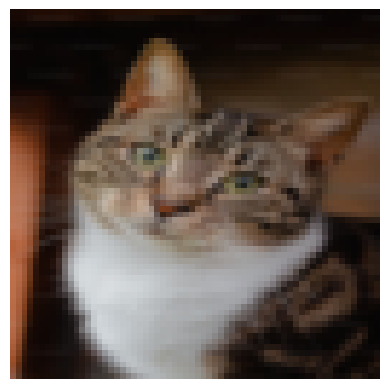

In [91]:
my_image = "cat_focus.png"
image, x_real_data = load_image(my_image)

plt.imshow(image)
plt.axis("off")

# logistic_prediction = classify(x_real_data, parameter_logistic_regression)
# print(f"Logistic Regression predict it's a {get_label(logistic_prediction)} picture")


# shallow_prediction = classify(x_real_data, parameter_shallow)
# print(f"Shallow Neural Network predict it's a {get_label(shallow_prediction)} picture")


deep_prediction = classify(x_real_data, parameter_deep)
print(f"Deep Neural Network predict it's a {get_label(deep_prediction)} picture")